### Goals

- gather models trained on different folds, with or without loc, with reports or country_id or without
- aggregate over diffferent folds
- with each model, predict the entire training dataset (through the different folds) 



In [1]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import os 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')

from evaluate import evaluate
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [2]:
api = wandb.Api(timeout=20)

#group_name = 'tabular data 4-fold crossval 5/4'
group_name = 'goldman vs. faostat vs. none 16/4 v2'
#group_name = 'one image 12/4'


runs = api.runs(path="janpisl/project_2", filters={"group": group_name, })

print(f"matching runs: {len(runs)}")

matching runs: 49


In [3]:
models = []

for i, run in enumerate(iter(runs)):
    model_dict = {}

    model_dict['config'] = run.config
    model_dict['wandb_id'] = run.id
    
    if len(run.summary.keys()) == 1: #This means there is no metrics -> killed or failed run
        continue
        
    model_dict['summary'] = run.summary
    
    name= " ".join(run.name.split())
    model_dict['name'] = name
    models.append(model_dict)

print(f'models: {len(models)}')

In [ ]:
#Optionally select only some experiments by name
#selected_models = [model for model in models if 'transform tab; transformer cls' in model['name']]  
#models = selected_models

In [4]:
for model in models:
    print(model['name'])

True img; yes loc; reports_token tabular; train [0, 1, 2] val [3]
True img; yes loc; reports_token tabular; train [0, 1, 3] val [2]
True img; yes loc; reports_token tabular; train [0, 2, 3] val [1]
True img; yes loc; reports_token tabular; train [1, 2, 3] val [0]
True img; yes loc; no tabular; train [0, 1, 2] val [3]
True img; yes loc; no tabular; train [0, 1, 3] val [2]
True img; yes loc; no tabular; train [0, 2, 3] val [1]
True img; yes loc; no tabular; train [1, 2, 3] val [0]
True img; no loc; reports_token tabular; train [0, 1, 2] val [3]
True img; no loc; reports_token tabular; train [0, 1, 3] val [2]
True img; no loc; reports_token tabular; train [0, 2, 3] val [1]
True img; no loc; reports_token tabular; train [1, 2, 3] val [0]
True img; no loc; no tabular; train [0, 1, 2] val [3]
True img; no loc; no tabular; train [0, 1, 3] val [2]
True img; no loc; no tabular; train [0, 2, 3] val [1]
True img; no loc; no tabular; train [1, 2, 3] val [0]
False img; yes loc; reports_token tabula

In [5]:
def invert_dict_list(input_dict):
    return {item: key for key, value_list in input_dict.items() for item in value_list}


# all wandb ids grouped by validation split
folds_to_models = {
    "val_0" : 
        [i['wandb_id'] for i  in models if i['config']['folds_to_split']['mapping']['0'] == 'val'],
    "val_1" : 
        [i['wandb_id'] for i  in models if i['config']['folds_to_split']['mapping']['1'] == 'val'],
    "val_2" : 
        [i['wandb_id'] for i  in models if i['config']['folds_to_split']['mapping']['2'] == 'val'],
    "val_3" : 
        [i['wandb_id'] for i  in models if i['config']['folds_to_split']['mapping']['3'] == 'val'],
}


models_to_folds =  invert_dict_list(folds_to_models)

In [6]:
datasets_by_fold = {}

#Prepare dataloaders for each fold
for key, value in folds_to_models.items():
    
    #Grab the first model of each fold to prepare dataloader (doesn't matter which one from the group)
    _id = value[0]
    
    model_dir = os.path.join('../models_trained', _id)
    config_path = os.path.join(model_dir, 'config.json')
    with open(config_path) as source:
        config = json.loads(source.read())
    
    dataloaders = dataloader.fetch_dataloader(
        ['val'], config)

    datasets_by_fold[key] = dataloaders['val']

In [7]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
n_classes = 12
num_images = 4


In [8]:
failed = {}

for i, model_dict in enumerate(models):
    print(i)
    wandb_id = model_dict['wandb_id']
    #try:
        
    model_dir = os.path.join('../models_trained', wandb_id)
    config_path = os.path.join(model_dir, 'config.json')
    with open(config_path) as source:
        config = json.loads(source.read())


    #Assign corresponding dataloader
    model_dict['val_dl'] = datasets_by_fold[models_to_folds[wandb_id]]


    #Load trained model
    model = MultiModalDriverClassifier(n_classes,  **config)
    model = model.to(device)

    trained_model_path = f'../models_trained/{wandb_id}/best.pt'
    _ = model.load_state_dict(torch.load(trained_model_path)['state_dict'])
    _ = model.eval()
    model.to(device)

    model_dict['model'] = model

    loss_fn = nn.CrossEntropyLoss(reduction='mean')


    config['wandb']['log_to_wandb'] = False

    metrics, preds, _ = evaluate(
        model=model_dict['model'], 
        loss_fn=loss_fn, 
        dataloader=model_dict['val_dl'], 
        device=device, 
        config=config,
        return_preds_and_targets=True
    )

    model_dict['predictions'] = preds
    model_dict['metrics'] = metrics
    #except Exception as e:
    #    failed[wandb_id] = e


0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27


In [9]:
pprint.pprint(failed)

{}


### Part 2


- aggregate models across folds

In [10]:
model_names = []

for i, model_dict in enumerate(models):
    _name = "".join(model_dict['name'].split(';')[:-1])
    #if model_dict['wandb_id'] in failed.keys():
    #    print(_name)
    model_names.append(_name)
    
model_names = list(set(model_names))

In [11]:
model_names

['True img yes loc reports_token tabular',
 'True img no loc no tabular',
 'False img yes loc no tabular',
 'False img no loc reports_token tabular',
 'True img no loc reports_token tabular',
 'False img yes loc reports_token tabular',
 'True img yes loc no tabular']

In [12]:
agg_models = {}

for model_name in model_names:
    agg_models[model_name] = [model_dict for model_dict in models if "".join(model_dict['name'].split(';')[:-1]) == model_name]


In [13]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv")

In [14]:
for model_name, model_group in agg_models.items():
    
    labels[model_name] = None
    
    for model_dict in model_group:

        val_dst = int(model_dict['name'].split('[')[-1].split(']')[0])
        try:
            
            labels.loc[labels['split'] == val_dst, model_name] = [inverse_label_mapping[i] for i in model_dict['predictions']]
        except KeyError:
            print(model_name)
            continue
    

In [15]:
#Excluding test set, keepin train + val
train_test = labels.loc[labels.split != 4]

In [16]:
columns_with_only_none = train_test.columns[train_test.isnull().all()].tolist()

In [17]:
df_filtered = train_test.drop(columns=columns_with_only_none)

In [18]:
df_filtered.columns

Index(['geometry', 'driver', 'sampleid', 'dataset', 'split', 'country',
       'True img yes loc reports_token tabular', 'True img no loc no tabular',
       'False img yes loc no tabular',
       'False img no loc reports_token tabular',
       'True img no loc reports_token tabular',
       'False img yes loc reports_token tabular',
       'True img yes loc no tabular'],
      dtype='object')

In [19]:
from sklearn.metrics import classification_report

In [20]:
'''cols_with_model_results = ['yes loc  reports_token tab transformer cls',
       'yes loc  reports_raw tab fc cls', 'yes loc  reports_token tab fc cls',
       'no loc  no tab transformer cls',
       'no loc  reports_token tab transformer cls',
       'no loc  reports_raw tab fc cls', 'yes loc  no tab transformer cls',
       'yes loc  no tab fc cls', 'no loc  reports_token tab fc cls',
       'no loc  no tab fc cls']'''


cols_with_model_results = ['True img yes loc reports_token tabular', 'True img no loc no tabular',
       'False img yes loc no tabular',
       'False img no loc reports_token tabular',
       'True img no loc reports_token tabular',
       'False img yes loc reports_token tabular',
       'True img yes loc no tabular']



In [21]:
for col in cols_with_model_results:
    metrics = pd.DataFrame(classification_report(df_filtered['driver'], df_filtered[col], output_dict=True))
    print(col, '; accuracy:', metrics['accuracy']['f1-score'])


True img yes loc reports_token tabular ; accuracy: 0.8849441157133465
True img no loc no tabular ; accuracy: 0.8269514158108322
False img yes loc no tabular ; accuracy: 0.625042508331633


/home/jan/miniconda3/envs/torch/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/jan/miniconda3/envs/torch/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/jan/miniconda3/envs/torch/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


False img no loc reports_token tabular ; accuracy: 0.45337686186492554
True img no loc reports_token tabular ; accuracy: 0.8743793783581582
False img yes loc reports_token tabular ; accuracy: 0.6299848103561632
True img yes loc no tabular ; accuracy: 0.8807499603255572


In [164]:
#Filter examples where base model is incorrect and tri-modal model is correct

fixed = df_filtered.loc[
    (df_filtered['no loc  no tab transformer cls'] != df_filtered['driver'])
     & 
    (df_filtered['yes loc  reports_token tab transformer cls'] == df_filtered['driver'])
     ]

In [163]:
#Filter examples where base model is correct and tri-modal model is not

incorrect = df_filtered.loc[
    (df_filtered['no loc  no tab transformer cls'] == df_filtered['driver'])
     & 
    (df_filtered['yes loc  reports_token tab transformer cls'] != df_filtered['driver'])
     ]

In [177]:
classes, fixed_counts  = np.unique(fixed.driver, return_counts=True)

In [178]:
classes, incorrect_counts = np.unique(incorrect.driver, return_counts=True)

In [179]:
incorrect_counts

array([  4,  29, 228, 392, 250, 183, 296,  92, 164,  18, 188, 114])

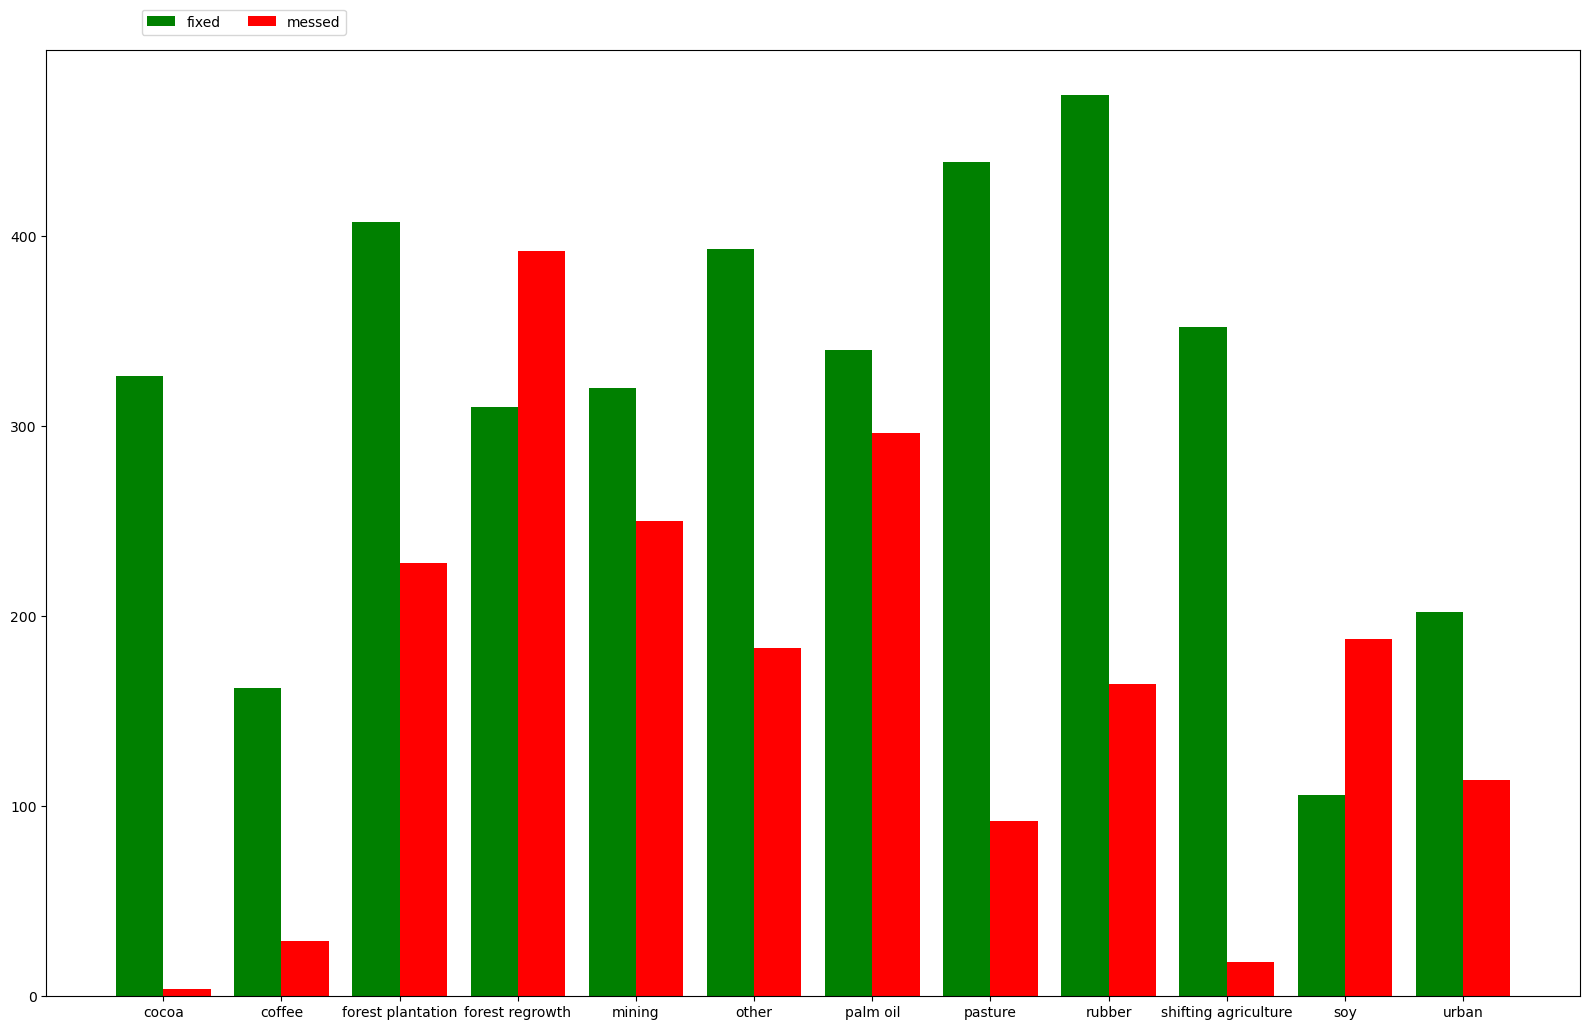

In [180]:

_x = np.arange(len(classes))  # the label locations
fig, ax = plt.subplots(1,figsize=(16,10))

ax.bar(_x-0.2, fixed_counts, width=0.4, color='green', align='center', label='fixed')
ax.bar(_x+0.2, incorrect_counts, width=0.4, color='red', align='center', label='messed')
plt.xticks(_x, classes) 
plt.tight_layout()
plt.legend(bbox_to_anchor=(0.2, 1.05), ncol=5)
plt.show()

In [182]:

cls, base_model_preds = np.unique(df_filtered['no loc  no tab transformer cls'], return_counts=True)
cls, trimodal_preds = np.unique(df_filtered['yes loc  reports_token tab transformer cls'], return_counts=True)

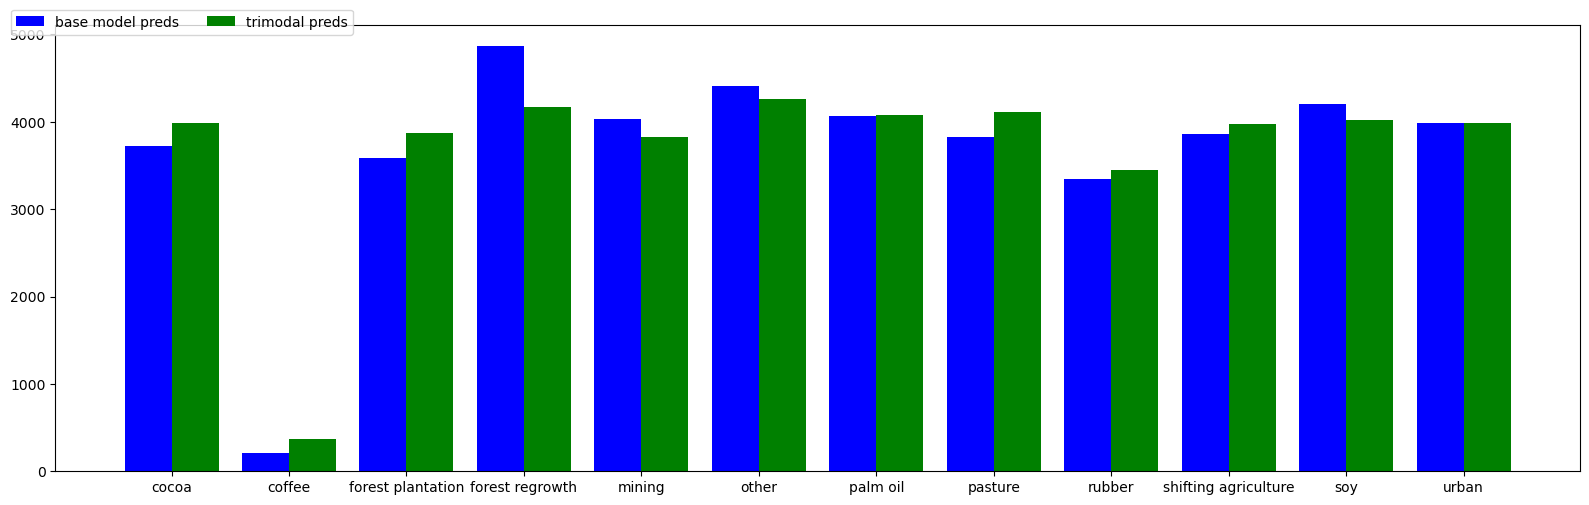

In [187]:

_x = np.arange(len(cls))  # the label locations
fig, ax = plt.subplots(1,figsize=(16,5))

ax.bar(_x-0.2, base_model_preds, width=0.4, color='blue', align='center', label='base model preds')
ax.bar(_x+0.2, trimodal_preds, width=0.4, color='green', align='center', label='trimodal preds')
plt.xticks(_x, classes) 
plt.tight_layout()
plt.legend(bbox_to_anchor=(0.2, 1.05), ncol=5)
plt.show()

In [198]:

    
incorrect_dict = dict(zip(*np.unique(incorrect.country, return_counts=True)))
fixed_dict = dict(zip(*np.unique(fixed.country, return_counts=True)))

In [201]:
for country in labels.country.unique():
    try:
        print(country)
        print('fixed: ',fixed_dict[country] , 'messed: ', incorrect_dict[country])
    except KeyError:
        continue

Ecuador
fixed:  245 messed:  25
Côte d'Ivoire
fixed:  21 messed:  2
Ghana
fixed:  77 messed:  57
Colombia
fixed:  26 messed:  13
Brazil
fixed:  1011 messed:  655
Viet Nam
fixed:  230 messed:  42
Indonesia
fixed:  1133 messed:  890
Malaysia
fixed:  101 messed:  69
Mexico
fixed:  13 messed:  2
Cuba
fixed:  11 messed:  7
Bolivia (Plurinational State of)
fixed:  5 messed:  2
United States of America
Australia
fixed:  3 messed:  3
Guatemala
fixed:  3 messed:  3
Philippines
fixed:  15 messed:  2
Lao People's Democratic Republic
fixed:  45 messed:  23
Peru
fixed:  56 messed:  1
Guyana
fixed:  18 messed:  3
India
fixed:  5 messed:  1
Democratic Republic of the Congo
fixed:  255 messed:  42
Papua New Guinea
fixed:  13 messed:  7
Gabon
fixed:  24 messed:  4
Uganda
fixed:  6 messed:  3
Venezuela (Bolivarian Republic of)
fixed:  14 messed:  3
Sri Lanka
Myanmar
fixed:  33 messed:  32
Suriname
Ethiopia
fixed:  2 messed:  1
Liberia
fixed:  8 messed:  1
Thailand
fixed:  178 messed:  18
Bahamas
Kenya
f

In [23]:

df_filtered

,geometry,driver,sampleid,dataset,split,country,True img yes loc reports_token tabular,True img no loc no tabular,False img yes loc no tabular,False img no loc reports_token tabular,True img no loc reports_token tabular,False img yes loc reports_token tabular,True img yes loc no tabular
1,POINT (-3.252726923505843 6.05540773743447),cocoa,30005848,cocoa.csv,1,Côte d'Ivoire,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
2,POINT (-1.8324904593128795 6.046244921563979),cocoa,30005875,cocoa.csv,1,Ghana,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
6,POINT (-0.7054641038565277 5.624755391523431),cocoa,30007242,cocoa.csv,0,Ghana,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
7,POINT (-79.5647662448441 -1.9379355564808602),cocoa,110003683,cocoa_ecuador.csv,0,Ecuador,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
9,POINT (-0.6413243925703949 6.412757556385085),cocoa,30004120,cocoa.csv,2,Ghana,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
...,...,...,...,...,...,...,...,...,...,...,...,...,...
55298,POINT (76.66305108549047 10.758438413532348),urban,100002981,worldcover.csv,1,India,urban,urban,urban,urban,urban,urban,urban
55299,POINT (106.68137671728651 -6.334442760971974),urban,100009782,worldcover.csv,1,Indonesia,urban,urban,other,other,urban,other,urban
55300,POINT (-35.322382484061244 -5.749666958458276),urban,10427227,mapbiomas.csv,2,Brazil,urban,urban,urban,pasture,urban,pasture,urban
55301,POINT (101.5439344788162 3.154945653990399),urban,100004466,worldcover.csv,1,Malaysia,urban,urban,urban,urban,urban,urban,urban


## Plot and check examples of (i) where the tri-modal helped and (ii) where it made it worse

In [24]:
df_filtered['True img yes loc reports_token tabular'] 

1        cocoa
2        cocoa
6        cocoa
7        cocoa
9        cocoa
         ...  
55298    urban
55299    urban
55300    urban
55301    urban
55302    urban
Name: True img yes loc reports_token tabular, Length: 44109, dtype: object

In [25]:

incorrect = df_filtered.loc[

    (df_filtered['True img yes loc reports_token tabular'] != df_filtered['driver'])
     ]

In [28]:
np.unique(incorrect['driver'], return_counts=True)

(array(['cocoa', 'coffee', 'forest plantation', 'forest regrowth',
        'mining', 'other', 'palm oil', 'pasture', 'rubber',
        'shifting agriculture', 'soy', 'urban'], dtype=object),
 array([ 24, 114, 819, 887, 560, 628, 734, 362, 494,  45, 215, 193]))